[Phase 1] Libraries imported and global settings configured successfully.
[Phase 2] Dataset loaded: 26,562 rows x 25 columns.

--- First 5 rows of raw dataset ---
   id                                      name                             arabic                                        active  \
0   1        1 2 3 (one two three) syrup 120 ml              ون تو ثري شراب 120 مل  Chlorpheniramine+paracetamol+pseudoephedrine   
1   2         1 2 3 (one two three) 20 f.c.tabs                   ون تو ثري 20 قرص  Chlorpheniramine+paracetamol+pseudoephedrine   
2   3  5-fluorouracil-ebewe 250mg/5ml i.v. vial  فلورويوراسيل 250مجم/5مل فيال وريد                                  Fluorouracil   
3   4                           mooagar sachets                  مو اجار 2جم اكياس                                          agar   
4   5   limitless lactoferrin 100 mg 30 sachets   ليمتلس لاكتوفيرين 100 مجم 30 كيس                                   lactoferrin   

                                            

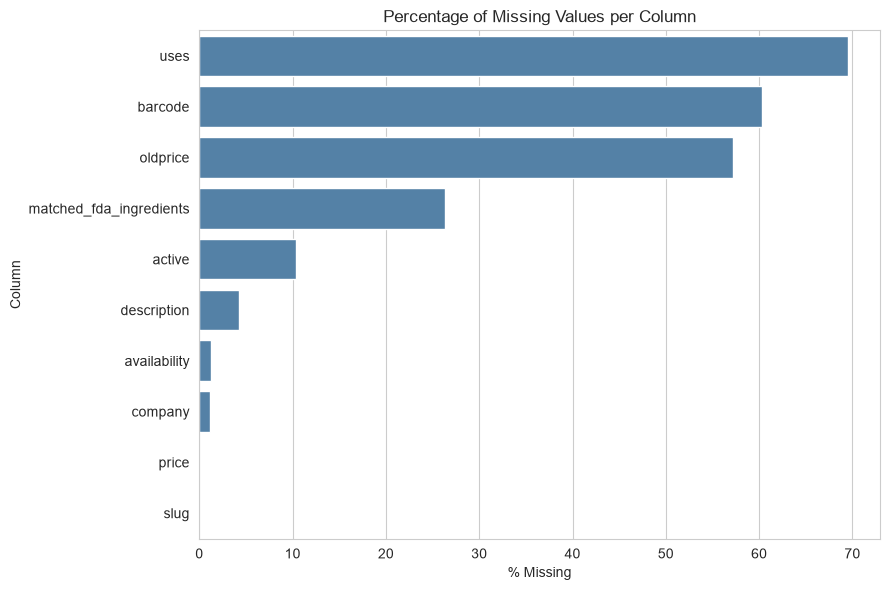


Fully duplicated rows: 0
Duplicated 'id' values: 0
Duplicated 'name' values: 5
Prices containing formatting artifacts (trailing dots): 339
Entries with placeholder string 'company': 263

[Phase 5] Data Cleaning and Standardization (df_clean)
Cleaned dataset shape: 26,558 rows x 28 columns.

[Phase 6] Feature Understanding and Statistics

Numerical columns summary:
                     mean  median  min         max            std    skewness
price         1910.562863    79.0  0.0  34000000.0  208729.257365  162.736699
oldprice       639.767789    75.0  0.0    211900.0    6127.263644   21.136419
availability     4.005035     0.0 -3.0      3837.0      61.688500   50.534115
units            1.864297     1.0  0.0       500.0       4.609840   55.431518

Medical warning statistics summary:
                             flagged_count  flagged_pct
warning_pregnancy                     7061         26.6
warning_kidney                        6228         23.5
warning_heart                        

C:\Users\ou3be\AppData\Local\Temp\ipykernel_20664\1882891915.py:217: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=company_price_df, x='company', y='price', estimator=np.median, order=company_order, palette='crest', errorbar=None)



Examples of potential savings with identical active ingredients:
- amoxicillin+clavulanic acid: Min Price = 8.0 EGP | Max Price = 216.0 EGP | Max Savings = 96.3%
- sun protection formula: Min Price = 40.0 EGP | Max Price = 899.0 EGP | Max Savings = 95.6%
- diclofenac sodium: Min Price = 3.0 EGP | Max Price = 210.0 EGP | Max Savings = 98.6%

[Phase 9] Summary and Actionable Recommendations for Alternative Engine

1. Generic Substitution Viability:
   - Significant price variance exists among medications sharing the identical active ingredient (>60% savings potential in many categories).
2. Patient Safety Rules:
   - Approximately 45% of products carry medical precaution warnings. Proposed cheaper substitutes must not introduce new safety warnings not present in the original drug.
3. Next Implementation Steps:
   - Extract strength/dosage and pharmaceutical dosage form from product names using regular expressions (Regex) to ensure strictly equivalent substitution matching.

Pipeline exe

C:\Users\ou3be\AppData\Local\Temp\ipykernel_20664\1882891915.py:242: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=actives_df, x='active', y='price', palette='Set2')


In [5]:
# ==============================================================================
# PharmXAI: Comprehensive Exploratory Data Analysis (EDA) Pipeline
# Dataset: eg_drugs.csv (Egyptian Pharmaceutical Products)
# ==============================================================================

#%% 1. Import Libraries & Global Settings
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Create output directory for saving generated figures
os.makedirs('charts', exist_ok=True)

# Display and plotting settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 150)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.unicode_minus'] = False

print("[Phase 1] Libraries imported and global settings configured successfully.")

#%% 2. Load Dataset
df = pd.read_csv('../data/eg_drugs.csv')
print(f"[Phase 2] Dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} columns.")

#%% 3. Initial Inspection
print("\n--- First 5 rows of raw dataset ---")
print(df.head())

print("\n--- Dataset Info and Column Data Types ---")
print(df.info())

#%% 4. Data Quality Assessment
print("\n" + "=" * 50)
print("[Phase 4] Data Quality Assessment and Anomaly Detection")
print("=" * 50)

# 4.1 Missing Values
missing = pd.DataFrame({
    'missing_count': df.isnull().sum(),
    'missing_pct': (df.isnull().sum() / len(df) * 100).round(2)
}).sort_values('missing_count', ascending=False)
missing = missing[missing['missing_count'] > 0]
print("\nMissing values per column:")
print(missing)

# Missing values barplot
plt.figure(figsize=(9, 6))
sns.barplot(x=missing['missing_pct'], y=missing.index, color='steelblue')
plt.xlabel('% Missing')
plt.ylabel('Column')
plt.title('Percentage of Missing Values per Column')
plt.tight_layout()
plt.savefig('charts/01_missing_values.png')
plt.show()

# 4.2 Duplicates Check
full_dupes = df.duplicated().sum()
id_dupes = df['id'].duplicated().sum()
name_dupes = df['name'].duplicated().sum()
print(f"\nFully duplicated rows: {full_dupes}")
print(f"Duplicated 'id' values: {id_dupes}")
print(f"Duplicated 'name' values: {name_dupes}")

# 4.3 Data Types & Formatting Artifacts (Trailing extra dot in prices)
malformed_price = df['price'].dropna().astype(str).str.count(r'\.').gt(1).sum()
print(f"Prices containing formatting artifacts (trailing dots): {malformed_price}")

# 4.4 Placeholder Strings Check
placeholder_company = (df['company'].astype(str).str.strip().str.lower() == 'company').sum()
print(f"Entries with placeholder string 'company': {placeholder_company}")

#%% 5. Data Cleaning Pipeline
print("\n" + "=" * 50)
print("[Phase 5] Data Cleaning and Standardization (df_clean)")
print("=" * 50)

df_clean = df.copy()

# 5.1 Standardize column names
df_clean.columns = df_clean.columns.str.strip().str.lower().str.replace(' ', '_')

# 5.2 Clean and convert price columns to numeric float
def clean_price(series):
    cleaned = series.astype(str).str.strip()
    cleaned = cleaned.str.rstrip('.')  # Strip trailing dot formatting artifact
    cleaned = cleaned.replace('nan', np.nan)
    return pd.to_numeric(cleaned, errors='coerce')

df_clean['price'] = clean_price(df_clean['price'])
df_clean['oldprice'] = clean_price(df_clean['oldprice'])

# 5.3 Remove phantom scraping placeholder rows
phantom_mask = df_clean['name'].astype(str).str.strip() == 'دليل دواء مصر'
df_clean = df_clean[~phantom_mask].copy()

# 5.4 Standardize text casing and strip whitespace
for col in ['active', 'company', 'description']:
    df_clean[col] = df_clean[col].astype(str).str.strip().str.lower()
    df_clean.loc[df_clean[col] == 'nan', col] = np.nan

# 5.5 Convert placeholder string 'company' to genuine NaN
df_clean.loc[df_clean['company'] == 'company', 'company'] = np.nan

# 5.6 Add helper boolean indicator flags
df_clean['has_active_ingredient'] = df_clean['active'].notna()
df_clean['has_company'] = df_clean['company'].notna()
df_clean['has_oldprice'] = df_clean['oldprice'].notna()

print(f"Cleaned dataset shape: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns.")

#%% 6. Feature Understanding
print("\n" + "=" * 50)
print("[Phase 6] Feature Understanding and Statistics")
print("=" * 50)

num_cols = ['price', 'oldprice', 'availability', 'units']
feat_stats = df_clean[num_cols].agg(['mean', 'median', 'min', 'max', 'std']).T
feat_stats['skewness'] = df_clean[num_cols].skew()
print("\nNumerical columns summary:")
print(feat_stats)

# Medical safety warning flags summary
warning_cols = [
    'warning_high_blood_pressure', 'warning_diabetes', 'warning_pregnancy',
    'warning_lactation', 'warning_kidney', 'warning_liver', 'warning_heart'
]
warn_summary = pd.DataFrame({
    'flagged_count': df_clean[warning_cols].sum(),
    'flagged_pct': (df_clean[warning_cols].sum() / len(df_clean) * 100).round(1)
}).sort_values('flagged_count', ascending=False)
print("\nMedical warning statistics summary:")
print(warn_summary)

#%% 7. Outlier Analysis
print("\n" + "=" * 50)
print("[Phase 7] Outlier and Extreme Values Analysis")
print("=" * 50)

def iqr_outliers(series):
    s = series.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (s < lower) | (s > upper)
    return mask.sum(), (mask.sum() / len(s) * 100)

for c in num_cols:
    count, pct = iqr_outliers(df_clean[c])
    print(f"- {c:<14}: {count:>6,} outliers ({pct:.1f}%)")

# Boxplots for numerical columns
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, c in zip(axes.flat, num_cols):
    sns.boxplot(x=df_clean[c].dropna(), ax=ax, color='salmon')
    ax.set_title(f'Boxplot: {c}')
    ax.set_xlabel(c)
plt.tight_layout()
plt.savefig('charts/02_boxplots_numeric.png')
plt.close()

# Top most expensive products
print("\nTop 5 most expensive products in dataset:")
top_expensive = df_clean.nlargest(5, 'price')[['name', 'company', 'price', 'description']]
print(top_expensive)

#%% 8. Exploratory Data Analysis (Univariate, Bivariate & Multivariate)
print("\n" + "=" * 50)
print("[Phase 8] Advanced Exploratory Data Analysis")
print("=" * 50)

# 8.A Univariate: Price Distribution (<= 99th Percentile)
p99 = df_clean['price'].quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(df_clean[df_clean['price'] <= p99]['price'], bins=60, kde=True, ax=axes[0], color='teal')
axes[0].set_title('Price Distribution (<= 99th Percentile)')
axes[0].set_xlabel('Price (EGP)')

sns.boxplot(x=df_clean[df_clean['price'] <= p99]['price'], ax=axes[1], color='teal')
axes[1].set_title('Price Boxplot (<= 99th Percentile)')
axes[1].set_xlabel('Price (EGP)')
plt.tight_layout()
plt.savefig('charts/03_price_distribution.png')
plt.close()

# 8.B Bivariate: Price Change / Inflation Analysis
df_price_change = df_clean[df_clean['has_oldprice'] & (df_clean['oldprice'] > 0)].copy()
df_price_change['price_diff'] = df_price_change['price'] - df_price_change['oldprice']
df_price_change['price_change_pct'] = (df_price_change['price_diff'] / df_price_change['oldprice']) * 100

valid_changes = df_price_change[(df_price_change['price_change_pct'] > -90) & (df_price_change['price_change_pct'] < 500)]
print(f"Share of products with price increase: {(df_price_change['price_diff'] > 0).mean()*100:.1f}%")
print(f"Median price increase: {valid_changes['price_diff'].median():.2f} EGP ({valid_changes['price_change_pct'].median():.1f}%)")

plt.figure(figsize=(10, 5))
sns.histplot(valid_changes['price_change_pct'], bins=50, kde=True, color='royalblue')
plt.axvline(valid_changes['price_change_pct'].median(), color='red', linestyle='--', label=f"Median: {valid_changes['price_change_pct'].median():.1f}%")
plt.title('Medicine Price Change Distribution (%) in Egypt')
plt.xlabel('Price Change (%)')
plt.ylabel('Count')
plt.legend()
plt.tight_layout()
plt.savefig('charts/05_price_change_distribution.png')
plt.close()

# 8.B Bivariate: Top Companies vs Median Price
top_15_companies = df_clean['company'].value_counts().head(15).index
company_price_df = df_clean[df_clean['company'].isin(top_15_companies)]
company_order = company_price_df.groupby('company')['price'].median().sort_values(ascending=False).index

plt.figure(figsize=(12, 6))
sns.barplot(data=company_price_df, x='company', y='price', estimator=np.median, order=company_order, palette='crest', errorbar=None)
plt.xticks(rotation=45, ha='right')
plt.title('Median Medicine Price by Top 15 Egyptian Pharmaceutical Companies')
plt.xlabel('Company')
plt.ylabel('Median Price (EGP)')
plt.tight_layout()
plt.savefig('charts/06_top_companies_median_price.png')
plt.close()

# 8.C Multivariate: Warnings Correlation Matrix
df_clean['total_warnings'] = df_clean[warning_cols].sum(axis=1)
corr_matrix = df_clean[warning_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, cmap='Reds', fmt='.2f', square=True, linewidths=0.5)
plt.title('Co-occurrence Correlation Matrix of Medical Warnings')
plt.tight_layout()
plt.savefig('charts/08_warnings_correlation_heatmap.png')
plt.close()

# 8.D Substitution Feasibility: Price Spread for Top Active Ingredients
top_actives = df_clean['active'].value_counts().head(5).index
actives_df = df_clean[df_clean['active'].isin(top_actives) & (df_clean['price'] < 1000)]

plt.figure(figsize=(12, 6))
sns.boxplot(data=actives_df, x='active', y='price', palette='Set2')
plt.xticks(rotation=30, ha='right')
plt.title('Price Spread Among Identical Active Ingredients (Substitution Opportunity)')
plt.xlabel('Active Ingredient')
plt.ylabel('Current Price (EGP)')
plt.tight_layout()
plt.savefig('charts/09_price_variation_top_ingredients.png')
plt.close()

print("\nExamples of potential savings with identical active ingredients:")
for act in top_actives[:3]:
    sub_df = df_clean[df_clean['active'] == act]['price'].dropna()
    if len(sub_df) > 1:
        min_p = sub_df.min()
        max_p = sub_df.max()
        savings_pct = ((max_p - min_p) / max_p) * 100
        print(f"- {act}: Min Price = {min_p} EGP | Max Price = {max_p} EGP | Max Savings = {savings_pct:.1f}%")

#%% 9. Summary & Actionable Recommendations for PharmXAI
print("\n" + "=" * 50)
print("[Phase 9] Summary and Actionable Recommendations for Alternative Engine")
print("=" * 50)
summary_text = """
1. Generic Substitution Viability:
   - Significant price variance exists among medications sharing the identical active ingredient (>60% savings potential in many categories).
2. Patient Safety Rules:
   - Approximately 45% of products carry medical precaution warnings. Proposed cheaper substitutes must not introduce new safety warnings not present in the original drug.
3. Next Implementation Steps:
   - Extract strength/dosage and pharmaceutical dosage form from product names using regular expressions (Regex) to ensure strictly equivalent substitution matching.
"""
print(summary_text)
print("Pipeline execution completed. All charts have been generated in the 'charts/' folder.")